# Complete Figure 3

[Figure 3 index](../README.md#figure-3).

This page assembles the three figure columns into one layout. The
plotting values and intervals are the same as in
[A](05_figure3a_exchange_patterns.ipynb),
[B](06_figure3b_tokens_by_rank.ipynb), and
[C](07_figure3c_cooperation_gap.ipynb). Each row has a colored
relationship header and each data panel carries its A–C label.

# Prepare the data and plotting functions

The auxiliary tables and their construction are explained in
[A](05_figure3a_exchange_patterns.ipynb),
[B](06_figure3b_tokens_by_rank.ipynb), and
[C](07_figure3c_cooperation_gap.ipynb). The chunks below repeat that
construction so this page can run on its own.

## Read the prepared data

In [ ]:
here::i_am("notebooks/main/figure3_assembly.qmd")
library(tidyverse)
library(here)
source(here("code", "00_style.R"))

The data are reused if `analysis_dyads` and `analysis_students` are
already in R. Otherwise, this step loads their CSV files from
`data/generated/main/`, or builds them from the raw inputs on first use.

In [ ]:
source(here("code", "00_load_main_data.R"), local = TRUE)
dyads <- analysis_dyads

In [ ]:
main_data_status

dataset,rows,source
analysis_dyads,17804,Saved CSV files
analysis_students,859,Saved CSV files


## Build the exchange cells for A

In [ ]:
# Panel A. Every pair exchanges two numbers: what i sends to j and what j
# sends to i. The order does not matter for the heatmap (5 and 2 is the same
# pair as 2 and 5), so we keep the larger number on the x axis and the
# smaller on the y axis. That is why the heatmap is a triangle.
#
# One-sided friendships appear twice in the data (as "Sender declares" from
# one side and "Receiver declares" from the other), so for the heatmap we put
# both together in one "Asymmetric" group. Percentages are computed within
# each group.

heatmap_cells <- dyads %>%
  mutate(group = case_when(friendship == "Non-friends" ~ "Non-friends",
                           friendship == "Mutual"      ~ "Mutual friends",
                           TRUE                        ~ "Asymmetric"),
         high = pmax(tokens_sent, tokens_received),
         low  = pmin(tokens_sent, tokens_received)) %>%
  count(group, high, low) %>%
  group_by(group) %>%
  mutate(percent = 100 * n / sum(n)) %>%
  ungroup() %>%
  # add the combinations that never happened, with 0%
  complete(group, high = 0:10, low = 0:10, fill = list(n = 0, percent = 0)) %>%
  filter(low <= high)

# Three regions highlighted in the paper
heatmap_regions <- heatmap_cells %>%
  group_by(group) %>%
  summarise(
    low_cooperation  = sum(percent[high <= 1]),                 # both sent 0 or 1 (magenta)
    asymmetric       = sum(percent[high == 10 & low <= 5]),     # one sent 10, the other 5 or less (blue)
    full_cooperation = sum(percent[high == 10 & low == 10])     # both sent 10 (black)
  )

heatmap_regions

## Build the child summaries and rank intervals for B and C

In [ ]:
# Panels B and C summarize transfers in two aggregation stages:
#
#   1. Summary by child. For each child (sender) and friendship group: her
#      mean tokens sent, her mean tokens received, her Cooperation GAP as the
#      difference between those two means (received - sent), and the median
#      Social Rank GAP of those partners. With observed transfers, panel C
#      equals the distance between the two mean curves of panel B.
#   2. Bins. The median rank gaps of the group are split into 7 intervals of
#      equal width ("round_gap"). The bins use all the children of the group,
#      so the observed and the filtered versions share the same bins.
#   3. Table of means by bin. Across the children of each bin: the mean and
#      SD of each measure, the position of the bin (mean of the children's
#      median gaps) and a 95% interval, mean +/- 1.96 * SD / sqrt(n), with n
#      the number of children in the bin.
#   4. The panels draw that table.
#
# Filtered version: a transfer dropped by the null-model filter is NA.
# Each direction keeps all of its retained transfers:
# the child's mean filtered tokens received minus her mean filtered tokens
# sent. (The filtered regressions, instead, use only pairs with both
# directions retained.) Children with nothing retained in one of the two
# directions have no filtered GAP; they stay in the total bin count n, and
# `n_with_value` counts finite child GAPs. The filtered sent, received, and GAP
# means can use different valid-child sets, so their bin-level difference
# need not equal the filtered GAP curve.

summary_by_child <- function(data, sent, received) {
  data %>%
    group_by(sender_id) %>%
    summarise(gap      = median(rank_gap),
              sent     = mean({{ sent }}, na.rm = TRUE),
              received = mean({{ received }}, na.rm = TRUE),
              .groups  = "drop") %>%
    mutate(dif_coop = received - sent)
}

summary_by_bin <- function(children, coef = 1.96, n_bins = 7) {
  children %>%
    mutate(round_gap = cut_interval(gap, n_bins, dig.lab = 1)) %>%
    group_by(round_gap) %>%
    summarise(median_gap    = mean(gap),     # position of the bin on the x axis
              n             = n(),
              n_with_value  = sum(is.finite(dif_coop)),
              mean_sent     = mean(sent, na.rm = TRUE),
              sd_sent       = sd(sent, na.rm = TRUE),
              mean_reci     = mean(received, na.rm = TRUE),
              sd_reci       = sd(received, na.rm = TRUE),
              mean_dif_coop = mean(dif_coop, na.rm = TRUE),
              sd_dif_coop   = sd(dif_coop, na.rm = TRUE),
              .groups = "drop") %>%
    mutate(se_sent     = coef * sd_sent / sqrt(n),
           se_reci     = coef * sd_reci / sqrt(n),
           se_dif_coop = coef * sd_dif_coop / sqrt(n))
}

rank_groups <- c("Non-friends", "Mutual", "Sender declares")

In [ ]:
# Step 1, for every friendship group, with observed and with filtered tokens
children <- map_dfr(rank_groups, function(this_group) {
  group_data <- dyads %>% filter(friendship == this_group)
  bind_rows(
    summary_by_child(group_data, tokens_sent, tokens_received) %>% mutate(version = "Observed"),
    summary_by_child(group_data, tokens_sent_filtered, tokens_received_filtered) %>% mutate(version = "Filtered")
  ) %>%
    mutate(group = this_group)
})

# a few children of the non-friends group, filtered tokens
children %>% filter(group == "Non-friends", version == "Filtered") %>% head()

In [ ]:
# Steps 2 and 3: the table of means by bin that the panels draw
binned <- children %>%
  group_by(group, version) %>%
  group_modify(~ summary_by_bin(.x)) %>%
  ungroup()

# Panel C, non-friends: Cooperation GAP by bin, observed and filtered
binned %>%
  filter(group == "Non-friends") %>%
  select(version, round_gap, median_gap, n, n_with_value, mean_dif_coop, se_dif_coop) %>%
  mutate(across(where(is.double), ~ round(.x, 2)))

## Define the plotting functions

These functions draw the nine panels from the auxiliary tables above.

In [ ]:
plot_heatmap <- function(this_group) {
  cells   <- heatmap_cells   %>% filter(group == this_group)
  regions <- heatmap_regions %>% filter(group == this_group)

  ggplot(cells, aes(x = high, y = low, fill = percent)) +
    geom_tile(color = "white") +
    geom_text(aes(label = round(percent, 1)), size = 2) +
    # magenta: low or no cooperation
    annotate("rect", xmin = -0.5, xmax = 1.5, ymin = -0.5, ymax = 1.5,
             color = "#F000D0", fill = NA, linewidth = 0.8) +
    annotate("label", x = 0.5, y = 2, label = round(regions$low_cooperation, 1),
             color = "#F000D0", size = 2.3, fontface = "bold") +
    # blue: highly asymmetric
    annotate("rect", xmin = 9.5, xmax = 10.5, ymin = -0.5, ymax = 5.5,
             color = "#173BFF", fill = NA, linewidth = 0.8) +
    annotate("label", x = 11, y = 5.5, label = round(regions$asymmetric, 1),
             color = "#173BFF", size = 2.3, fontface = "bold") +
    # black: full mutual cooperation
    annotate("rect", xmin = 9.5, xmax = 10.5, ymin = 9.5, ymax = 10.5,
             color = "black", fill = NA, linewidth = 0.9) +
    scale_fill_gradientn(colours = c("#FFF4D6", "#F7E08A", "#E7B56A", "#D9874C", "#C95A3A", "#A51C1C"),
                         values = scales::rescale(c(0, 2, 5, 10, 15, 20)),
                         limits = c(0, 20), oob = scales::squish, name = "%") +
    scale_x_continuous(breaks = 0:10, expand = c(0, 0)) +
    scale_y_continuous(breaks = 0:10, expand = c(0, 0)) +
    coord_fixed(clip = "off") +
    labs(x = "Tokens i to j", y = "Tokens j to i", title = this_group) +
    theme_paper(base_size = 9) +
    theme(panel.border = element_blank(), legend.position = "right")
}

In [ ]:
mean_tokens <- mean(dyads$tokens_sent)

# Reuse this plotting specification for any relationship group.
plot_tokens <- function(this_group, color, version = "Observed") {
  bins <- binned %>% filter(group == this_group, version == !!version)

  ggplot(bins, aes(x = median_gap)) +
    geom_vline(xintercept = 0, linetype = "dashed", color = "grey40") +
    geom_hline(yintercept = mean_tokens, linetype = "dashed", color = "grey50") +
    # yellow area between the two mean curves (the observed Cooperation GAP)
    geom_ribbon(aes(ymin = mean_reci, ymax = mean_sent), fill = "#F0E5A8", alpha = 0.7) +
    # sent: rhombi
    geom_line(aes(y = mean_sent), color = color, linewidth = 0.9) +
    geom_errorbar(aes(ymin = mean_sent - se_sent, ymax = mean_sent + se_sent),
                  color = color, width = 0.04) +
    geom_point(aes(y = mean_sent), color = color, shape = 18, size = 3) +
    # received: squares
    geom_line(aes(y = mean_reci), color = color, linewidth = 0.9) +
    geom_errorbar(aes(ymin = mean_reci - se_reci, ymax = mean_reci + se_reci),
                  color = color, width = 0.04) +
    geom_point(aes(y = mean_reci), color = color, shape = 15, size = 2.5) +
    annotate("text", x = c(-0.55, 0.55), y = 0.4, size = 2.3, fontface = "bold",
             label = c("Receiver higher rank", "Sender higher rank")) +
    scale_x_continuous(limits = c(-1.1, 1.1), breaks = seq(-1, 1, 0.5)) +
    scale_y_continuous(limits = c(0, 11), breaks = c(0, 5, 10)) +
    labs(x = "Social Rank GAP", y = "Tokens") +
    theme_paper(base_size = 9)
}

In [ ]:
# Reuse the same specification, with optional emphasis and limits.
plot_coop_gap <- function(this_group, color, y_limits = c(-6, 6), main = "Observed",
                          short_labels = FALSE) {
  bins <- binned %>% filter(group == this_group, is.finite(mean_dif_coop))
  back <- setdiff(c("Observed", "Filtered"), main)
  curve_labels <- c(Observed = "Observed data", Filtered = "Null-model filtered")

  ggplot(bins, aes(x = median_gap, y = mean_dif_coop, alpha = version)) +
    geom_vline(xintercept = 0, linetype = "dashed", color = "grey40") +
    geom_hline(yintercept = 0, linetype = "dashed", color = "grey40") +
    geom_line(color = color, linewidth = 0.9) +
    geom_errorbar(aes(ymin = mean_dif_coop - se_dif_coop, ymax = mean_dif_coop + se_dif_coop),
                  color = color, width = 0.04) +
    geom_point(color = color, size = 2.8) +
    scale_alpha_manual(values = setNames(c(1, 0.4), c(main, back))) +
    annotate("text", x = c(-0.55, 0.55), y = y_limits[1] + 0.4, size = 2.3, fontface = "bold",
             label = c("Receiver higher rank", "Sender higher rank")) +
    {if (short_labels)
      annotate("text", x = c(0.42, 1.08), y = y_limits[1] + 1.4, hjust = 1, size = 2.2,
               fontface = "bold", color = color, alpha = c(1, 0.5), label = c(main, back))
     else
      annotate("text", x = 1.05, y = y_limits[2] - c(0.3, 1.1), hjust = 1, size = 2.5,
               fontface = "bold", color = color, alpha = c(1, 0.4),
               label = curve_labels[c(main, back)])} +
    scale_x_continuous(limits = c(-1.1, 1.1), breaks = seq(-1, 1, 0.5)) +
    scale_y_continuous(limits = y_limits, breaks = seq(-7.5, 5, 2.5)) +
    labs(x = "Social Rank GAP", y = "Cooperation GAP\n[Received - Sent]") +
    theme_paper(base_size = 9)
}

# Row headers and layout

The layout functions use the figure color roles and the shared export
helper. The three rows are I, non-friends; II, mutual friends; and III,
sender-declared one-sided friendships. In row III, A includes both
nomination directions while B and C use the sender-declared direction.

In [ ]:
library(patchwork)
source(here::here("code", "theme_hierarchy_20261121.R"))

In [ ]:
figure3_row_header <- function(roman, label, color) {
  ggplot() +
    annotate("rect", xmin = 0, xmax = 1, ymin = 0, ymax = 1,
             fill = color, color = NA) +
    annotate("text", x = 0.02, y = 0.5, label = roman, hjust = 0,
             color = "white", fontface = "bold", size = 5) +
    annotate("text", x = 0.52, y = 0.5, label = label,
             color = "white", fontface = "bold", size = 5) +
    scale_x_continuous(limits = c(0, 1), expand = c(0, 0)) +
    scale_y_continuous(limits = c(0, 1), expand = c(0, 0)) +
    theme_hierarchy(base_size = 16) +
    theme(axis.title = element_blank(), axis.text = element_blank(),
          axis.line = element_blank(), axis.line.x.bottom = element_blank(),
          axis.line.y.left = element_blank(), panel.border = element_blank(),
          plot.margin = margin(0, 0, 0, 0))
}

assemble_figure3 <- function(heatmap, tokens, cooperation_gap) {
  tag_panel <- function(plot, letter) {
    plot + labs(title = paste0(letter, ".")) +
      theme(plot.title = theme_hierarchy(base_size = 14)$plot.title)
  }

  row_non_friends <-
    tag_panel(heatmap("Non-friends"), "A") |
    tag_panel(tokens("Non-friends", pal_category[["Non Friends"]]), "B") |
    tag_panel(cooperation_gap("Non-friends", pal_category[["Non Friends"]]), "C")

  row_mutual <-
    tag_panel(heatmap("Mutual friends"), "A") |
    tag_panel(tokens("Mutual", pal_category[["Mutual"]]), "B") |
    tag_panel(cooperation_gap("Mutual", pal_category[["Mutual"]]), "C")

  row_one_sided <-
    tag_panel(heatmap("Asymmetric"), "A") |
    tag_panel(tokens("Sender declares", pal_category[["Ego declares"]]), "B") |
    tag_panel(cooperation_gap("Sender declares", pal_category[["Ego declares"]],
                             y_limits = c(-8.5, 6)), "C")

  figure3_row_header("I", "Non-friends", pal_category[["Non Friends"]]) /
    row_non_friends /
    figure3_row_header("II", "Mutual friends", pal_category[["Mutual"]]) /
    row_mutual /
    figure3_row_header("III", "Sender-declared one-sided friendships",
                       pal_category[["Ego declares"]]) /
    row_one_sided +
    plot_layout(heights = c(0.13, 1, 0.13, 1, 0.13, 1))
}

# Complete Figure 3

In [ ]:
figure3_assembled <- assemble_figure3(plot_heatmap, plot_tokens, plot_coop_gap)

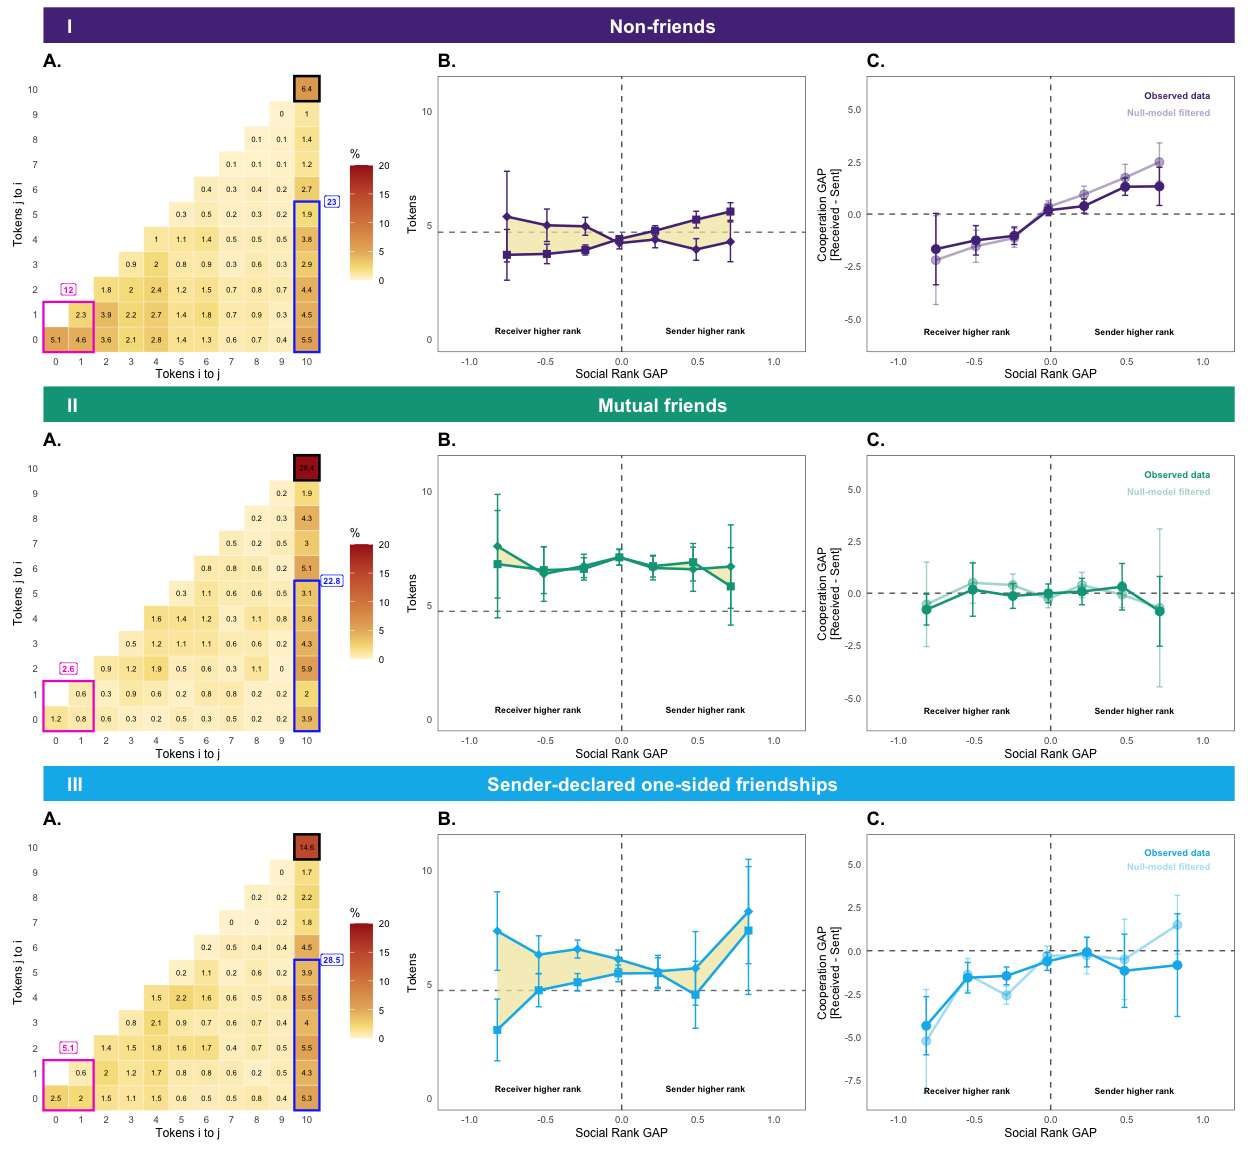

In [ ]:
figure3_assembled

# Export the assembled figure

In [ ]:
save_fig(figure3_assembled,
         here("output", "figures", "figure3_assembled_20261121"),
         class = "main_heatmap")

[Download PDF](figure3_assembled_20261121.pdf) · [Download
PNG](figure3_assembled_20261121.png).

# Session information

In [ ]:
sessionInfo()
## R version 4.3.2 (2023-10-31)
## Platform: aarch64-apple-darwin20 (64-bit)
## Running under: macOS 26.7.1
## 
## Matrix products: default
## BLAS:   /Library/Frameworks/R.framework/Versions/4.3-arm64/Resources/lib/libRblas.0.dylib 
## LAPACK: /Library/Frameworks/R.framework/Versions/4.3-arm64/Resources/lib/libRlapack.dylib;  LAPACK version 3.11.0
## 
## locale:
## [1] C.UTF-8/C.UTF-8/C.UTF-8/C/C.UTF-8/C.UTF-8
## 
## time zone: America/Santiago
## tzcode source: internal
## 
## attached base packages:
## [1] stats     graphics  grDevices utils     datasets  methods   base     
## 
## other attached packages:
##  [1] patchwork_1.3.0 lubridate_1.9.4 forcats_1.0.0   stringr_1.5.1  
##  [5] dplyr_1.1.4     purrr_1.0.4     readr_2.1.5     tidyr_1.3.1    
##  [9] tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0 here_1.0.1     
## 
## loaded via a namespace (and not attached):
##  [1] bit_4.6.0         gtable_0.3.6      jsonlite_2.0.0    crayon_1.5.3     
##  [5] compiler_4.3.2    tidyselect_1.2.1  parallel_4.3.2    textshaping_1.0.0
##  [9] systemfonts_1.2.2 scales_1.3.0      yaml_2.3.10       fastmap_1.2.0    
## [13] R6_2.6.1          labeling_0.4.3    generics_0.1.3    knitr_1.50       
## [17] munsell_0.5.1     rprojroot_2.0.4   pillar_1.10.2     tzdb_0.5.0       
## [21] rlang_1.1.6       stringi_1.8.7     xfun_0.52         bit64_4.6.0-1    
## [25] timechange_0.3.0  cli_3.6.4         withr_3.0.2       magrittr_2.0.3   
## [29] digest_0.6.37     grid_4.3.2        vroom_1.6.5       hms_1.1.3        
## [33] lifecycle_1.0.4   vctrs_0.6.5       evaluate_1.0.3    glue_1.8.0       
## [37] farver_2.1.2      ragg_1.3.3        colorspace_2.1-1  rmarkdown_2.29   
## [41] tools_4.3.2       pkgconfig_2.0.3   htmltools_0.5.8.1

[Continue to numbers cited in the main text](08_numbers_in_text.ipynb).